Modeling the effects of Tectonic Uplift on River Profile Evolution

Group Members: David Ammons ans Logan Kofod

Earth System Modeling: Final Project

Presentation Date: Dec 3, 2026

Introduction:

Landscape evolution is the process of how Earth's surface changes over time. These changes are caused from tectonic uplift, river erosion, and hillslope erosion, these processes work together to form mountains, valleys, and river networks. It is important for us to understand how landscapes evolve because it helps us to study the relationships between tectonic activity, climate, and erosion.

Scientists use landscape evolution models to study topography and how it responds to changes in tectonics and climate, these models use stream power incision models to describe river erosion and diffusion equations in order to describe hillslope erosion. They used methods like finite differences and finite volumes are used in order to solve these equations. These methods have limitations though because they require small time steps in order to maintain stability and introduce numerical diffusion, which can affect the accuracy of the results.

Steer (2021) developed a new approach that was called Saleve that he used to model ladscape evolution in two dimensions. The method that he developed solves the linear stream power equation analytically in order to determine how elevation changes along river flow paths. This was different from standard numerical methods because this approach avoiuds numerical diffusion and it does not have the same numerical stability restrictions on timestep size as the traditional methods. The model can calculate steady state landscapes and simulate how topography changes over time under different uplift conditions.

In the study Steer (2021) compared the analytical model with his numerical solutions and examines how accuratelty each method represented the landscape evolution. The results that he found showed that the analytical approach coulkd be used reproduce the expected relationships between river slope and drainage area while also reducing some of the errors that were associated witht he small time steps in numerical methods. However the paper also identifies its limitations, such as the possibility of abrupt topographic changes when the river networks reorganize themselves.

For our project our plan is for us to use the stream power erosion equation the Steer (2021) presented to investigate how different tectonic uplift rates effect the river profile evolution. Instead of modeling an entire two dimensional landscape we will consolidate the model in order to focus on the elevation changes along a single river flow path. We'll compare simulations with different uplift rates so that we can examine how river elevation, slope and profile shape change over time.

Scientific Question: How does changing the rate of techtonic uplift affect the elevation and the evolution of river profiles over time?

Equations:
Physical Process
We modeled detachement limited river incision in a landscape uplifted by tectonics. Rock uplift at rate $U$ raises the river bed, while erosion proportional to the river's drainage area and slope lowers it. Changes in uplift generate Knickpoints (sharp slope breaks) that migrate upstream as kinematic waves [Whipple & Tucker, 1999; Royden & Perron, 2013].

Governing Equation:
Mass conservation of the river bed elevation $z(l,t)$, with $l$ the distance along the river from the outlet:

$$\frac{\partial z}{\partial t} = U(l,t) - E, \qquad E = K' Q_w^{,m} \left (\frac){\partial z}{\partial l}\right)^n$$

Where $Q_w = rA$ is water discharge ($r$ = mean runoff, $A$ = drainage area). Defining the effective erodibility $K = K' r^m$ gives the stream power incision model (SPIM):

$$\frac{\partial z}{\partial t} = U - K A^m \left(\frac{\partial z}{\partial l}\right)^n$$

For $n=1$ this is a linear advection (kinematic wave) equation with wave speed independent of slope:

$$\frac{\partial z}{\partial t} + C(1)\frac{\partial z}{\partial l} = U, \qquad C(1) = K A(1)^m$$

Drainage area (Hack's law)
$$A(l) = k_a, l^{1/h}$$ with $h \approx 0.65$ (Hack, 1957; the value found in Steer, 2021) and $k_a$ a constant.

Analytical solution (method of characteristics)
Along characteristics $dl/dt = C(l)$ the elevation changes at rate $dz/dt = U$. The time for a wave to travel from the outlet to position $l$ is the response time

$$\tau(l) = \int_0^l \frac{dl'}{K A(l')^m}$$

Steady state ($\partial z/\partial t = 0$): $; z(l) = z_{base} + U,\tau(l)$
Build-up from a flat bed (Steer, 2021, Eq. 6): $; z(l,t) = z_{base} + U\min(\tau(l),,t)$
Uplift step $U_1 \to U_2$ at $t_0$: $; z(l,t) = z_{base} + U_1\tau(l) + (U_2-U_1)\min(\tau(l),,t-t_0)$. The knickpoint is located where $\tau(l) = t - t_0$.
Terms and parameters
Symbol	Meaning	Value (Steer, 2021)	Units
$z$	river bed elevation	—	m
$l$	distance from outlet	0 to $L$	m
$U$	rock uplift rate	10 (then 20) mm/yr	m/yr
$K'$	erodibility	$10^{-6}$	check units
$r$	mean runoff	5/365	m/day
$m, n$	area and slope exponents	0.5, 1	–
$h$	Hack exponent	0.65	–
Boundary and initial conditions
BC: fixed base level at the outlet, $z(0,t) = z_{base}$. The equation is hyperbolic with information traveling upstream, so no BC is needed at the upstream end.
IC: (a) flat bed $z(l,0)=z_{base}$, or (b) the steady profile for $U_1$ before the uplift step.
Assumptions
Detachment-limited (no sediment transport or deposition)
Linear SPIM ($n=1$)
Single, fixed flow path with $A(l)$ from Hack's law (no river capture or network reorganization)
Spatially uniform $K$, $r$, $U$ (uplift can change in time)
No horizontal tectonic motion; hillslope and colluvial processes neglected


Numerical Methods:

For our model, we are going to be using the finite difference method in order to solve the linear stream power incision equation. This method will allow us to divide the river into a series of evenly spaced points and calculate how the elevation at each point changes over time.

We will use an explicite upwind finite difference methond since the changes in river elevation propagate upstream from the river outlet. This methods uses the elevation differenvce between two neighboring points in order to calculate the local river slope and to determine the rate of erosion.

We decided that we would do the explicit upwind finite difference method isntead of other methods because it was simple to implements and it was appropriate for us to use to model the upstream propagation of changes in rever elevation. THe explicit method will allow us to claculate elevation at each time step without solving a system of equations, which we would not be able to do if we used implicit finite difference methods.

We'll run multiple simulations using different tectonic uplift rates while we use different tectonic uplift rates and we'll keep the other physical parameters constant. THis will allow us to isolate the effects of uplifting on the river profile evolution.

We are also going to compare our numerical results with the analytical solutions presented by Steer (2021) in oreder to evaluate the accuracy of our model. Different spatial resolutions and wime steps will be used and tested for us to determine how these numerical parameters affect our results.



Discretization of the Governing Equation

To solve the governing equation numerically, we must approximate the time and spatial derivatives using finite differences.

The governing equation is:

$$\frac{\partial z}{\partial t}=U-KA^m\frac{\partial z}{\partial l}$$

We use a forward difference to approximate the time derivative:

$$\frac{\partial z}{\partial t}\approx\frac{z_i^{j+1}-z_i^j}{\Delta t}$$

We use a backward difference to approximate the spatial derivative:

$$\frac{\partial z}{\partial l}\approx\frac{z_i^j-z_{i-1}^j}{\Delta l}$$

Where:
- $i$ is the spatial grid point.
- $j$ is the current time step.
- $j+1$ is the next time step.
- $\Delta t$ is the time-step size.
- $\Delta l$ is the distance between grid points.

Substituting these approximations into the governing equation gives:

$$\frac{z_i^{j+1}-z_i^j}{\Delta t}=U-KA_i^m\frac{z_i^j-z_{i-1}^j}{\Delta l}$$

Rearranging to solve for elevation at the next time step gives:

$$z_i^{j+1}=z_i^j+\Delta t\left(U-KA_i^m\frac{z_i^j-z_{i-1}^j}{\Delta l}\right)$$

This equation will be used to calculate the elevation at each grid point at every time step throughout our simulation.

    

### Numerical Stability Condition

Since we are using an explicit finite difference method, we need to make sure that our time-step size is small enough to maintain numerical stability. To do this, we will use the Courant-Friedrichs-Lewy (CFL) condition.

The speed at which changes in elevation propagate upstream is:

$$C(l)=KA(l)^m$$

The stability condition for our numerical method is:

$$\frac{C_{\max}\Delta t}{\Delta l}\leq 1$$

Rearranging this equation allows us to determine the maximum allowable time-step size:

$$\Delta t_{\max}=\frac{\Delta l}{C_{\max}}$$

For our simulations, we will use a Courant number of 0.8 to remain below the stability limit:

$$\Delta t=0.8\frac{\Delta l}{C_{\max}}$$

This ensures that changes in elevation do not propagate farther than one spatial grid interval during a single time step. We will also test different Courant numbers to examine how the time-step size affects the accuracy of our numerical results.

In [4]:
import numpy as np
import matplotlib.pyplot as plt

#Physical parameteres
L= 1000
U= 0.01
K= 1e-6
m = 0.5
n=1
h = 0.65
zbase=0

##numeriacl parameters
dl =50
CFL = 0.8
tend =500000

In [7]:
#grid
l=np.arange(0, L+dl,dl)
N = len(l)



print ("Number of grid points:", N)
print("River length:", L, "m")
print("Grid spacing:", dl, "m")

Number of grid points: 21
River length: 1000 m
Grid spacing: 50 m


Calculating drainage area 

GOnna try and use Hack's law to calculate the drainage area at each point along the river
$$A(l)=A_{\min}+k_a(L-l)^{1/h}$$
Since we're measuring the distance from the river outlet, the drainage area will decrease as we move upstream. We assume a max drainage area of 100 km^2 at the outlet and a minimum drainage area of 2,500 m^2 at the headwaters.


Drainage area at outlet: 100000000.0 m^2
Drainage area at headwaters: 2500.0 m^2


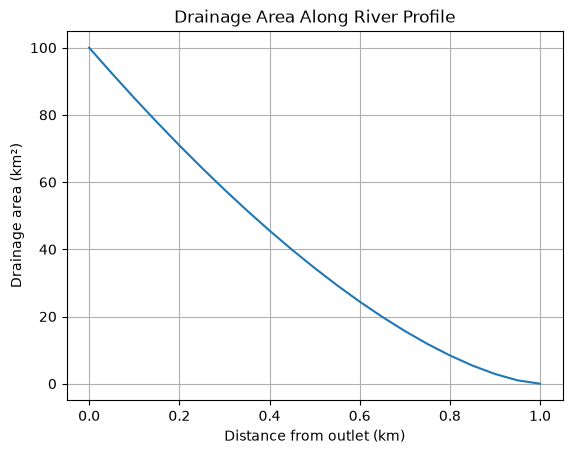

In [10]:
##Drainage using Hack's law
Amin= 2500
Amax =1e8
ka=(Amax- Amin) /L**(1/h)
A = Amin+ ka* (L-l)**(1/h)

print ("Drainage area at outlet:", A[0],"m^2")
print("Drainage area at headwaters:", A[-1], "m^2")

plt.plot(l/1000, A/1e6)
plt.xlabel("Distance from outlet (km)")
plt.ylabel("Drainage area (km²)")
plt.title("Drainage Area Along River Profile")
plt.grid()
plt.show()